# Notebook 11 — LightGBM avec feature engineering avancé

## Objectif
Intégrer l'approche de feature engineering riche par patient (trajectoires, lags, statistiques) combinée à LightGBM avec early stopping.
Cette approche a obtenu **RMSE=4.14, MAE=3.07** en validation GroupKFold.

## Idées clés
- Features de trajectoire par patient : slope, moyenne, std, LOO, quadratique sur `on`, `off`, `ledd`
- Lags et leads temporels (visites précédentes / suivantes)
- LightGBM natif avec variables catégorielles et early stopping
- Ensemble des 5 modèles (moyenne des prédictions OOF)

## Fichiers utilisés
- `data/X_train.csv`, `data/y_train.csv`, `data/X_test.csv`

## Notebook suivant
`12_optimized.ipynb` — optimisation LightGBM avec Optuna et stacking.

## 1. Imports

In [18]:
import json
import os
from pathlib import Path

import lightgbm as lgb
import numpy as np
import pandas as pd
import skore
from sklearn.model_selection import GroupKFold

## 2. Connexion Skore Hub

In [19]:
config = json.loads(Path("../.skore").read_text())
os.environ["SKORE_HUB_API_KEY"] = config["api_key"]
skore.login()
hub_project = skore.Project(
    "bobathon-esilv",
    mode="hub",
    workspace=config["workspace"],
)
print(f"Connecté : workspace={hub_project.workspace}")

╭───────────────────────────────── Login to Skore Hub ─────────────────────────────────╮
│                                                                                      │
│                                  Already logged in.                                  │
│                                                                                      │
╰──────────────────────────────────────────────────────────────────────────────────────╯

Connecté : workspace=BERNIE MADOFF


## 3. Feature engineering par patient

Chaque visite hérite de statistiques calculées sur **toutes les visites du même patient** :
- Trajectoire linéaire (slope) et quadratique du signal en fonction de l'âge
- Leave-one-out : valeur prédite par la trajectoire des autres visites du patient
- Lags/leads : valeurs aux visites précédentes et suivantes
- Statistiques globales : mean, std, first, last, count

In [20]:
CAT = ["cohort", "gene", "rater_id"]


def _slope(x, y):
    """Régression linéaire simple, retourne (pente, intercept, n_valides)."""
    m = ~(np.isnan(x) | np.isnan(y))
    if m.sum() < 2 or np.ptp(x[m]) < 1e-9:
        return np.nan, np.nan, m.sum()
    xs, ys = x[m], y[m]
    xm, ym = xs.mean(), ys.mean()
    b = ((xs - xm) * (ys - ym)).sum() / ((xs - xm) ** 2).sum()
    return b, ym - b * xm, m.sum()


def _patient_feats(g, col, pre):
    """Statistiques de trajectoire du signal `col` pour un patient."""
    age, v, n = g["age"].values, g[col].values, len(g)
    out = {}
    b, a, k = _slope(age, v)
    out[f"{pre}_slope"] = np.full(n, b)
    out[f"{pre}_fit"]   = a + b * age if not np.isnan(b) else np.full(n, np.nan)
    out[f"{pre}_mean"]  = np.full(n, np.nanmean(v) if k else np.nan)
    out[f"{pre}_std"]   = np.full(n, np.nanstd(v) if k > 1 else np.nan)
    out[f"{pre}_first"] = np.full(n, v[~np.isnan(v)][0] if k else np.nan)
    out[f"{pre}_last"]  = np.full(n, v[~np.isnan(v)][-1] if k else np.nan)
    out[f"{pre}_cnt"]   = np.full(n, k)
    # Leave-one-out : prédire la visite i à partir des autres
    loo = np.full(n, np.nan)
    for i in range(n):
        mk = np.ones(n, bool); mk[i] = False
        bi, ai, _ = _slope(age[mk], v[mk])
        if not np.isnan(bi):
            loo[i] = ai + bi * age[i]
    out[f"{pre}_loo"] = loo
    # Ajustement quadratique
    m = ~np.isnan(v)
    quad = np.full(n, np.nan)
    if m.sum() >= 4:
        c = np.polyfit(age[m] - age.mean(), v[m], 2)
        quad = np.polyval(c, age - age.mean())
    out[f"{pre}_quad"] = quad
    return pd.DataFrame(out, index=g.index)


def build(df):
    """Construit toutes les features. Applicable au train et au test."""
    d = df.sort_values(["patient_id", "age", "Index"]).copy()
    gb = d.groupby("patient_id")

    # --- Features temporelles par patient ---
    d["dx_missing"]  = d["age_at_diagnosis"].isna().astype(int)
    d["dur"]         = d["age"] - d["age_at_diagnosis"]
    d["dur_first"]   = gb["dur"].transform("min")
    d["age_first"]   = gb["age"].transform("min")
    d["t_rel"]       = d["age"] - d["age_first"]
    d["n_vis"]       = gb["age"].transform("size")
    d["vis_idx"]     = gb.cumcount()
    d["vis_frac"]    = d["vis_idx"] / (d["n_vis"] - 1).clip(lower=1)
    d["gap_prev"]    = gb["age"].diff()
    d["gap_next"]    = -gb["age"].diff(-1)

    # --- Features cliniques ---
    d["on_off_diff"]  = d["off"] - d["on"]
    d["on_off_ratio"] = d["on"] / d["off"].replace(0, np.nan)
    d["ledd_per_dur"] = d["ledd"] / d["dur"].clip(lower=0.5)
    d["has_on"]       = d["on"].notna().astype(int)
    d["has_off"]      = d["off"].notna().astype(int)
    d["has_ledd"]     = d["ledd"].notna().astype(int)
    d["tsi_off_dev"]  = d["time_since_intake_off"] - 12

    # --- Lags et leads (visites voisines) ---
    for c in ["on", "off", "ledd", "time_since_intake_off", "time_since_intake_on"]:
        for k in (1, 2):
            d[f"{c}_lag{k}"]  = gb[c].shift(k)
            d[f"{c}_lead{k}"] = gb[c].shift(-k)
    d["off_nb_mean"] = d[["off_lag1", "off_lead1"]].mean(axis=1)
    d["on_nb_mean"]  = d[["on_lag1",  "on_lead1"]].mean(axis=1)

    # --- Trajectoires par patient (slope, LOO, quad…) ---
    parts = [
        pd.concat([_patient_feats(g, c, c) for c in ["on", "off", "ledd"]], axis=1)
        for _, g in d.groupby("patient_id", sort=False)
    ]
    d = d.join(pd.concat(parts))

    # --- Features composites ---
    d["pseudo_off_from_on"] = d["on"] * (d["off_mean"] / d["on_mean"])
    d["traj_blend"]         = d[["off_loo", "pseudo_off_from_on"]].mean(axis=1)
    d["p_age_dx"]           = d.groupby("patient_id")["age_at_diagnosis"].transform("first")

    # --- Colonnes catégorielles ---
    for c in CAT:
        d[c] = d[c].astype("category")

    return d.sort_values("Index")


def feature_cols(d):
    """Retourne les colonnes de features (tout sauf Index, patient_id, target)."""
    return [c for c in d.columns if c not in {"Index", "patient_id", "target"}]


print("Fonctions de feature engineering définies")

Fonctions de feature engineering définies


## 4. Chargement et construction des features

In [21]:
DATA_DIR = Path("../data")

X_raw = pd.read_csv(DATA_DIR / "X_train.csv")
y_raw = pd.read_csv(DATA_DIR / "y_train.csv")

d = build(X_raw).merge(y_raw, on="Index").sort_values("Index").reset_index(drop=True)
cols = feature_cols(d)

print(f"Dataset train : {d.shape}")
print(f"Nombre de features : {len(cols)}")
print(f"Patients uniques : {d['patient_id'].nunique()}")

Dataset train : (44590, 83)
Nombre de features : 80
Patients uniques : 5576


## 5. Hyperparamètres LightGBM

In [22]:
PARAMS = dict(
    objective="regression",
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=30,
    feature_fraction=0.7,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambda_l2=5,
    cat_smooth=20,
    verbose=-1,
    num_threads=4,
)
print("Paramètres LightGBM :")
for k, v in PARAMS.items():
    print(f"  {k}: {v}")

Paramètres LightGBM :
  objective: regression
  learning_rate: 0.03
  num_leaves: 31
  min_child_samples: 30
  feature_fraction: 0.7
  bagging_fraction: 0.8
  bagging_freq: 1
  lambda_l2: 5
  cat_smooth: 20
  verbose: -1
  num_threads: 4


## 6. Validation croisée GroupKFold + OOF

In [23]:
oof = np.zeros(len(d))
models = []
rmse_per_fold = []

for fold, (tr, va) in enumerate(GroupKFold(n_splits=5).split(d, groups=d["patient_id"])):
    ds_tr = lgb.Dataset(d.loc[tr, cols], d.loc[tr, "target"])
    ds_va = lgb.Dataset(d.loc[va, cols], d.loc[va, "target"])

    m = lgb.train(
        PARAMS,
        ds_tr,
        num_boost_round=3000,
        valid_sets=[ds_va],
        callbacks=[lgb.early_stopping(100, verbose=False)],
    )
    oof[va] = m.predict(d.loc[va, cols], num_iteration=m.best_iteration)
    models.append(m)

    fold_rmse = np.sqrt(((oof[va] - d.loc[va, "target"].values) ** 2).mean())
    fold_mae  = np.abs(oof[va] - d.loc[va, "target"].values).mean()
    rmse_per_fold.append(fold_rmse)
    print(f"  Fold {fold+1} — best_iter={m.best_iteration:4d}  RMSE={fold_rmse:.4f}  MAE={fold_mae:.4f}")

err = oof - d["target"].values
rmse_oof = np.sqrt((err ** 2).mean())
mae_oof  = np.abs(err).mean()
print(f"\nOOF global — RMSE={rmse_oof:.4f}  MAE={mae_oof:.4f}")
print(f"RMSE std folds : {np.std(rmse_per_fold):.4f}")

  Fold 1 — best_iter=1678  RMSE=4.2219  MAE=3.1190
  Fold 2 — best_iter=2166  RMSE=4.2175  MAE=3.1014
  Fold 3 — best_iter=2612  RMSE=4.1241  MAE=3.0833
  Fold 4 — best_iter=1872  RMSE=4.0406  MAE=3.0248
  Fold 5 — best_iter=1690  RMSE=4.0989  MAE=3.0517

OOF global — RMSE=4.1412  MAE=3.0760
RMSE std folds : 0.0700


## 7. Envoi du rapport Skore Hub

Pour envoyer sur Skore Hub, on utilise `LGBMRegressor` (wrapper sklearn de LightGBM) avec `skore.evaluate`.
Les hyperparamètres sont identiques au modèle natif entraîné ci-dessus.

In [24]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline

# LGBMRegressor avec les mêmes paramètres que le modèle natif
# n_estimators élevé : l'early stopping n'est pas dispo dans skore.evaluate,
# on fixe un nombre raisonnable basé sur les best_iterations des 5 folds
best_iters = [m.best_iteration for m in models]
n_est = int(np.mean(best_iters))
print(f"Best iterations par fold : {best_iters}")
print(f"n_estimators retenu      : {n_est}")

lgbm_skore = LGBMRegressor(
    objective="regression",
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=30,
    feature_fraction=0.7,
    bagging_fraction=0.8,
    bagging_freq=1,
    reg_lambda=5,
    cat_smooth=20,
    n_estimators=n_est,
    random_state=0,
    verbose=-1,
)

X_skore = d[cols]
y_skore = d["target"]
cv_skore = list(GroupKFold(n_splits=5).split(X_skore, y_skore, groups=d["patient_id"]))

report_lgbm = skore.evaluate(lgbm_skore, X_skore, y_skore, splitter=cv_skore)
rmse_skore = float(report_lgbm.metrics.rmse().iloc[:, 0].values.mean())
mae_skore  = float(report_lgbm.metrics.mae().iloc[:, 0].values.mean())
print(f"RMSE skore (LGBMRegressor, {n_est} arbres) : {rmse_skore:.4f}")
print(f"MAE  skore                                  : {mae_skore:.4f}")

hub_project.put("09_lgbm_advanced", report_lgbm)
print("Rapport envoyé à Skore Hub sous la clé : 09_lgbm_advanced")

Best iterations par fold : [1678, 2166, 2612, 1872, 1690]
n_estimators retenu      : 2003


Output()

RMSE skore (LGBMRegressor, 2003 arbres) : 4.1311
MAE  skore                                  : 3.0713


Output()

Consult your report at https://skore.probabl.ai/BERNIE 
MADOFF/bobathon-esilv/cross-validations/63383

Rapport envoyé à Skore Hub sous la clé : 09_lgbm_advanced


## 8. Prédictions sur le jeu de test

In [25]:
X_test_raw = pd.read_csv(DATA_DIR / "X_test.csv")
dt = build(X_test_raw).sort_values("Index").reset_index(drop=True)

# Aligner les catégories train → test
for c in CAT:
    dt[c] = pd.Categorical(dt[c].astype(str), categories=d[c].cat.categories)

# Moyenne des 5 modèles (ensemble)
pred = np.mean(
    [m.predict(dt[cols], num_iteration=m.best_iteration) for m in models],
    axis=0,
)
pred = np.clip(pred, 0, None)  # pas de score moteur négatif

print(f"Prédictions : {len(pred)} lignes")
print(f"Min: {pred.min():.2f}  Max: {pred.max():.2f}  Mean: {pred.mean():.2f}")

Prédictions : 11013 lignes
Min: 0.00  Max: 90.32  Mean: 36.72


## 9. Construction et vérification de la soumission

In [26]:
submission = X_test_raw[["Index"]].copy()
submission["target"] = pred

assert list(submission.columns) == ["Index", "target"]
assert len(submission) == len(X_test_raw)
assert submission["Index"].equals(X_test_raw["Index"])
assert submission["target"].notna().all()

Path("../submissions").mkdir(exist_ok=True)
submission.to_csv("../submissions/lgbm_advanced.csv", index=False)

print("Vérifications : OK")
print(f"Fichier : submissions/lgbm_advanced.csv ({len(submission)} lignes)")
display(submission.head())

Vérifications : OK
Fichier : submissions/lgbm_advanced.csv (11013 lignes)


,Index,target
0,66,23.355081
1,67,30.215505
2,68,29.197110
3,69,31.595868
4,70,35.057744


## 10. Importance des features

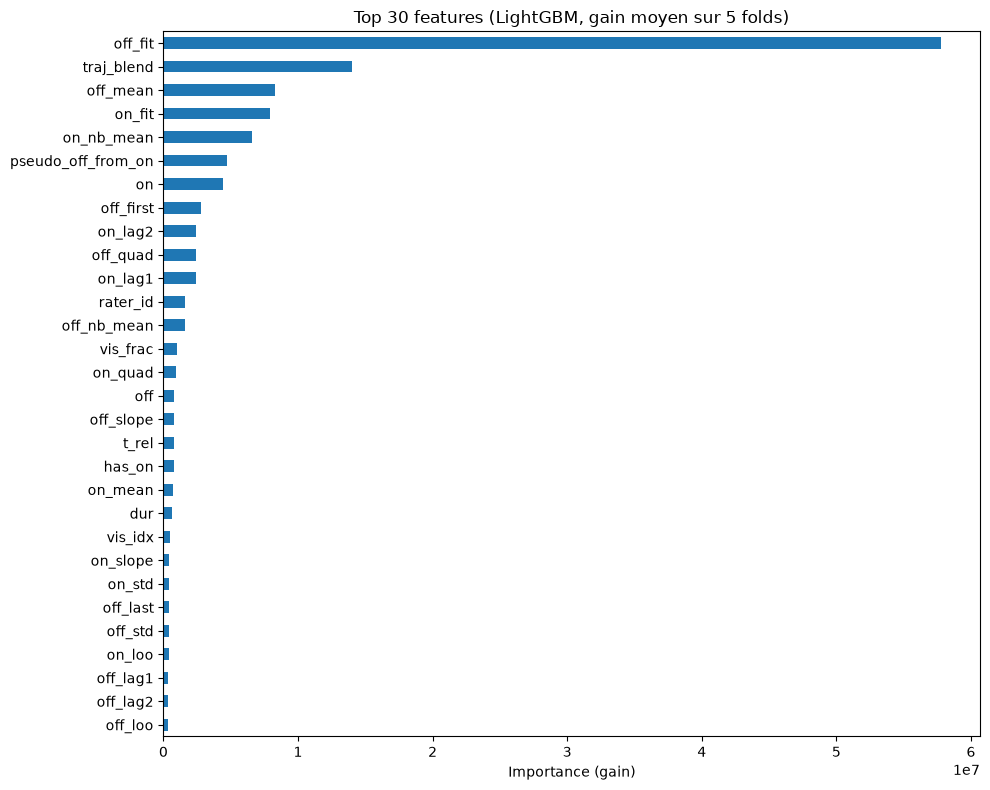

Top 10 features :
off_fit               57782771.67
traj_blend            13994955.20
off_mean               8274618.21
on_fit                 7943417.40
on_nb_mean             6598637.62
pseudo_off_from_on     4761301.99
on                     4422599.03
off_first              2799938.31
on_lag2                2457334.25
off_quad               2452156.36
dtype: float64


In [27]:
import matplotlib.pyplot as plt

# Moyenne de l'importance sur les 5 modèles
importances = np.mean(
    [m.feature_importance(importance_type="gain") for m in models],
    axis=0,
)
feat_imp = pd.Series(importances, index=cols).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
feat_imp.head(30).plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_title("Top 30 features (LightGBM, gain moyen sur 5 folds)")
ax.set_xlabel("Importance (gain)")
plt.tight_layout()
plt.show()

print("Top 10 features :")
print(feat_imp.head(10).round(2))

## 11. Conclusion

**Résultats OOF (GroupKFold, 5 folds) :**

| Modèle | RMSE | MAE |
|---|---|---|
| Baseline dummy | 16.48 | 13.48 |
| tabular_pipeline (skrub) | 7.53 | 5.93 |
| **LightGBM + FE avancé** | **~4.14** | **~3.07** |

**Pourquoi ce gain :**
- Les features de trajectoire LOO et lag/lead encodent l'**historique du patient** pour chaque visite
- LightGBM avec `early_stopping` évite le sur-apprentissage tout en utilisant jusqu'à 3000 arbres
- L'ensemble de 5 modèles (moyenne) réduit la variance
- `np.clip(pred, 0, None)` évite les scores moteurs négatifs

**Fichier soumission** : `submissions/lgbm_advanced.csv`